# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import HRCWHUDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 150


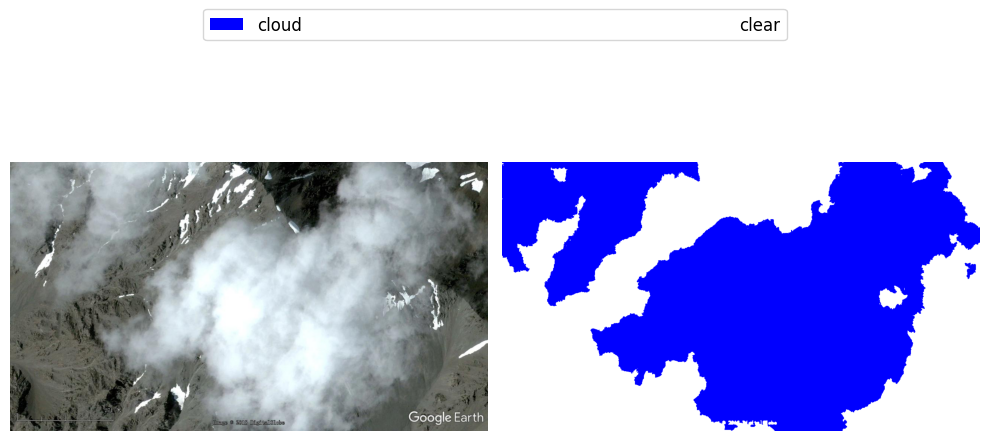

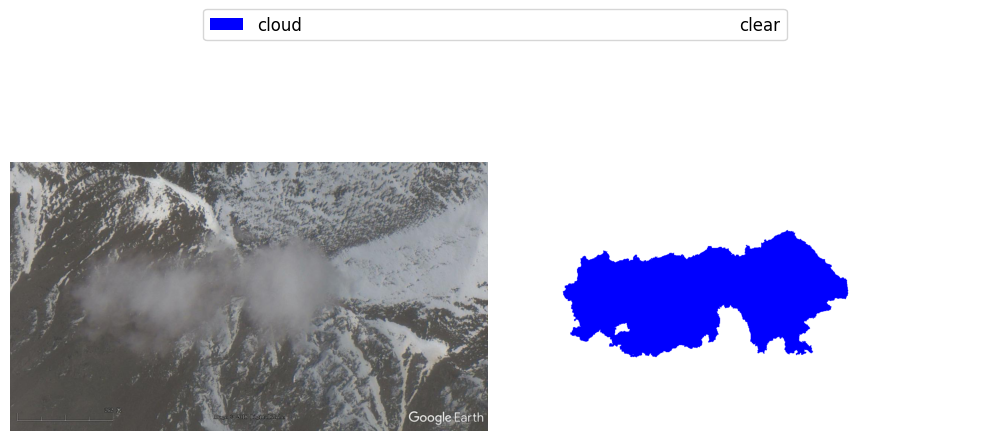

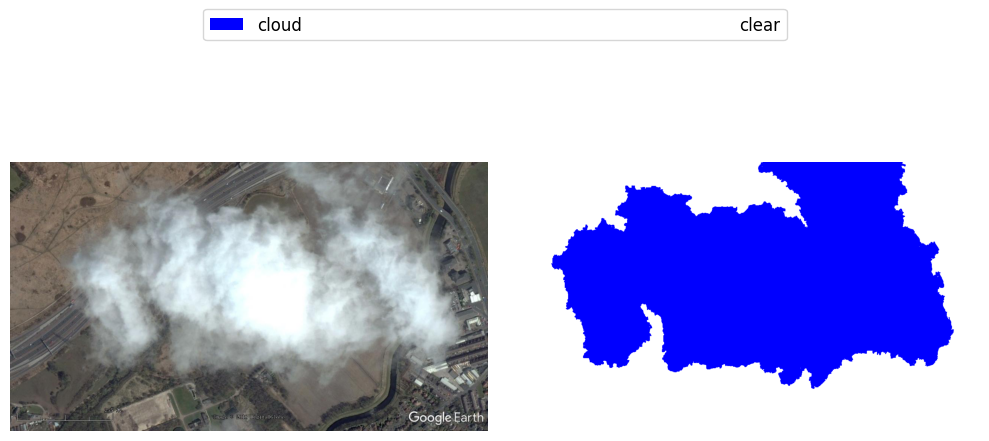

In [15]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/HRC_WHU"
}
dataset = HRCWHUDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

In [16]:
dataset.data_distribution_table()

,Number of pixels
cloud,47319853.0
clear,90989267.0


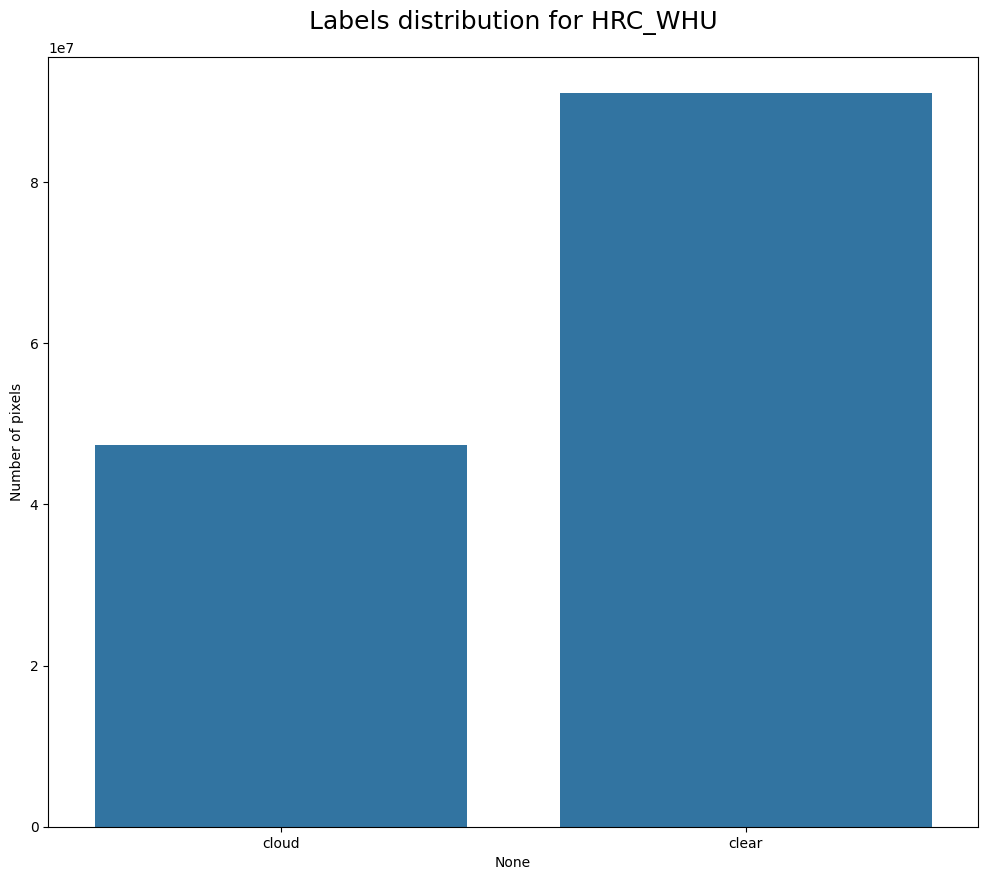

In [17]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/HRC_WHU/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = HRCWHUDataset(train_dataset_config)
len(train_dataset)

120

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/HRC_WHU"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-03 14:28:35,133 INFO Starting training.
training: 100%|██████████| 15/15 [01:19<00:00,  5.32s/it]
2025-03-03 14:29:54,963 INFO epoch: 1, time: 79, loss:  0.44771
testing on train set: 100%|██████████| 15/15 [01:19<00:00,  5.31s/it]
2025-03-03 14:31:16,086 INFO IOU:0.6551800004248514, IOU mean:0.6410326707008532, IOU per Class:[0.56365647 0.71840887]
training: 100%|██████████| 15/15 [01:19<00:00,  5.32s/it]
2025-03-03 14:32:35,871 INFO epoch: 2, time: 79, loss:  0.31125
testing on train set: 100%|██████████| 15/15 [01:19<00:00,  5.31s/it]
2025-03-03 14:33:55,584 INFO IOU:0.7913641129052543, IOU mean:0.7730851547994093, IOU per Class:[0.70251493 0.84365538]
training: 100%|██████████| 15/15 [01:19<00:00,  5.32s/it]
2025-03-03 14:35:15,358 INFO epoch: 3, time: 80, loss:  0.25083
testing on train set: 100%|██████████| 15/15 [01:19<00:00,  5.33s/it]
2025-03-03 14:36:35,310 INFO IOU:0.7960942496365644, IOU mean:0.7778291009959799, IOU per Class:[0.69480832 0.86084988]
training: 100%|█

## Evaluate the model

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/HRC_WHU/test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = HRCWHUDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/HRC_WHU/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

30


2025-03-03 14:55:30,642 INFO Loading checkpoint /home/dragik/data/FAIR_EO/HRC_WHU/checkpoint.pth.tar
2025-03-03 14:55:30,982 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/HRC_WHU/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 8/8 [00:20<00:00,  2.53s/it]


[{'IOU': 0.8659726850294639,
  'IOU mean': 0.8590089975611478,
  'IOU per Class': array([0.82129667, 0.89672133])}]

## Predictions

2025-03-10 09:40:34,832 INFO Loading checkpoint /home/dragik/data/FAIR_EO/HRC_WHU/checkpoint.pth.tar
2025-03-10 09:40:35,216 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/HRC_WHU/checkpoint.pth.tar at epoch 11


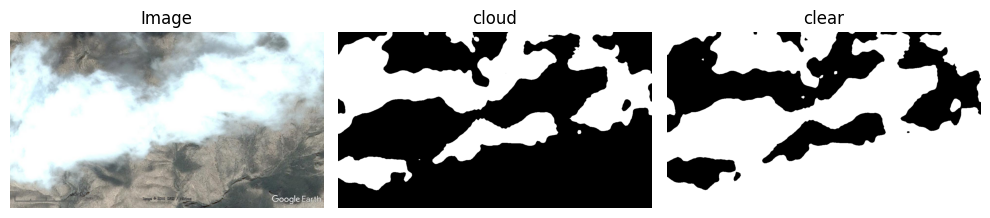

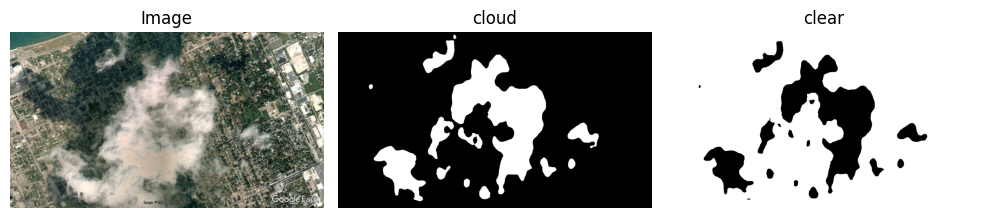

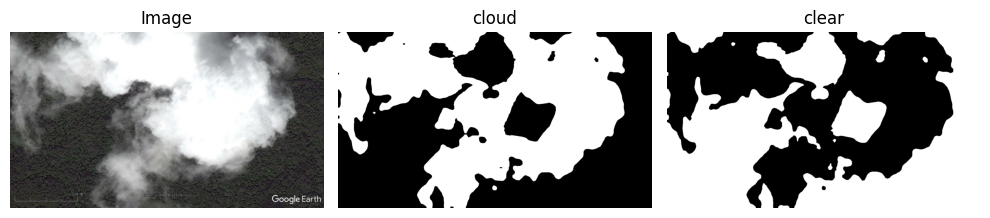

In [6]:
model_path = "/home/dragik/data/FAIR_EO/HRC_WHU/checkpoint.pth.tar"
labels = ["cloud","clear"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/HRC_WHU/test/images/barren_25.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HRC_WHU/test/images/urban_21.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HRC_WHU/test/images/vegetation_29.tif')
fig = model.predict_masks(image, labels, transform)